In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

$y' = F(t,y) $ 
`solve_ivp( F, (t0, T), [y0] )` $y_0= y(t_0) $

In [2]:
def f(t,y):
    return np.sin(t) - y/2.
def y_exact(t):
    return 2./5* np.sin(t) - 4./5 * np.cos(t) + 9./5 * np.exp(-t/2)

True


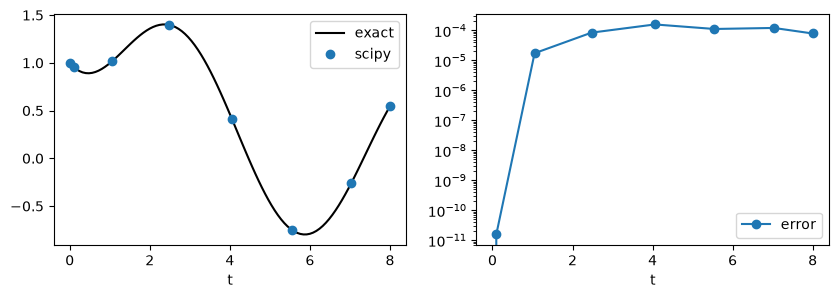

In [7]:
sol = solve_ivp(f, (0,8), [1])
print(sol.success)
# print(sol.t, sol.y[0])
fig, ax = plt.subplots(1,2, figsize=(10,3))
tt = np.linspace(0,8,101)
ax[0].plot(tt, y_exact(tt), "k-", label="exact")
ax[0].plot(sol.t, sol.y[0], "o", label="scipy")
ax[1].semilogy(sol.t, np.abs(sol.y[0] - y_exact(sol.t)), "o-", label="error") 
for i in [0,1]:
    ax[i].set_xlabel("t")
    ax[i].legend()
plt.show()

True


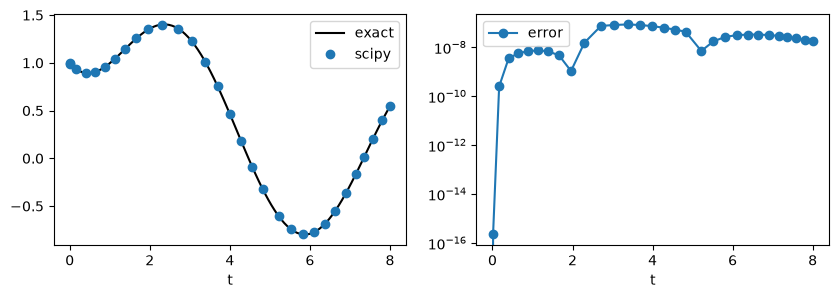

In [11]:
tt = np.linspace(0,8,101)
sol = solve_ivp(f, (0,8), [1], rtol=1e-7, atol=1e-9)
print(sol.success)
# print(sol.t, sol.y[0])
fig, ax = plt.subplots(1,2, figsize=(10,3))
ax[0].plot(tt, y_exact(tt), "k-", label="exact")
ax[0].plot(sol.t, sol.y[0], "o", label="scipy")
ax[1].semilogy(sol.t, np.abs(sol.y[0] - y_exact(sol.t)), "o-", label="error") 
for i in [0,1]:
    ax[i].set_xlabel("t")
    ax[i].legend()
plt.show()

In [13]:
for rtol in [1e-4, 1e-7, 1e-10]:
    sol = solve_ivp(f, (0,8), [1], rtol=rtol, atol=0.1*rtol)
    print("T:", sol.t[-1], "y(T):", sol.y[0,-1], "f eval:", sol.nfev)

T: 8.0 y(T): 0.5451245231601014 f eval: 74
T: 8.0 y(T): 0.5451114863716421 f eval: 194
T: 8.0 y(T): 0.5451114756620488 f eval: 662


True 0.999927638717339 1000000.0001459023 1


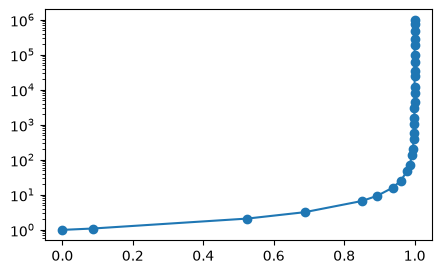

In [23]:
def f(t,y):
    return y**2 
def y_exact(t):
    return 1./(1-t)
def ev(t,y):
    return y[0] - 1e6
ev.terminal = True
sol =solve_ivp(f, (0,2), [1], events= ev)
print(sol.success, sol.t[-1], sol.y[0,-1], sol.status)

fig,ax = plt.subplots(figsize=(5,3))
ax.semilogy(sol.t, sol.y[0], "o-")
plt.show()